<a href="https://colab.research.google.com/github/uranovnass/task/blob/main/ml11_C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install umap-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness

import umap.umap_ as umap

# Загружаем данные
data = load_breast_cancer()

X = data.data
y = data.target

# Масштабирование
X_scaled = StandardScaler().fit_transform(X)

print("Размер данных:", X.shape)
print("Количество классов:", len(np.unique(y)))

Размер данных: (569, 30)
Количество классов: 2


In [3]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

print(
    "PCA, доля дисперсии:",
    np.round(pca_2d.explained_variance_ratio_, 3)
)

print(
    "Сумма:",
    round(pca_2d.explained_variance_ratio_.sum(), 3)
)

PCA, доля дисперсии: [0.443 0.19 ]
Сумма: 0.632


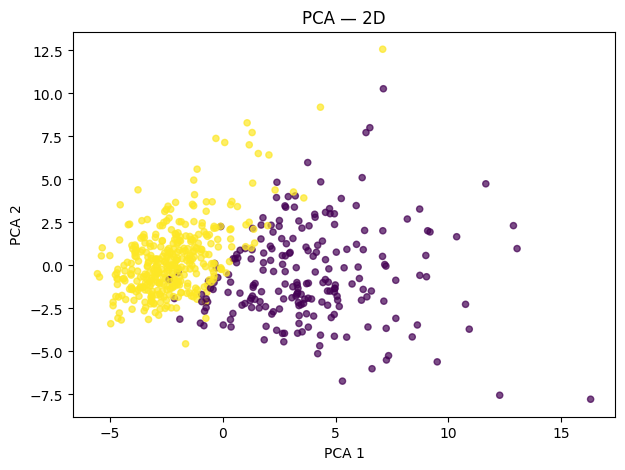

In [4]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    s=20,
    alpha=0.7
)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("PCA — 2D")
plt.show()

In [5]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

print("t-SNE готов:", X_tsne.shape)

t-SNE готов: (569, 2)


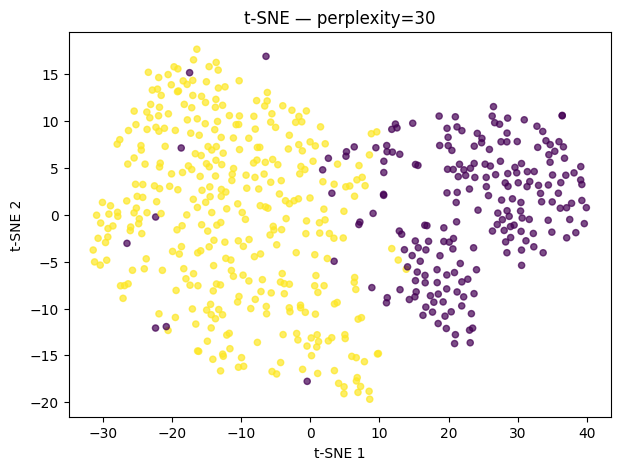

In [6]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y,
    s=20,
    alpha=0.7
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE — perplexity=30")
plt.show()

In [7]:
umap_model = umap.UMAP(
    n_components=2,
    random_state=42
)

X_umap = umap_model.fit_transform(X_scaled)

print("UMAP готов:", X_umap.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP готов: (569, 2)


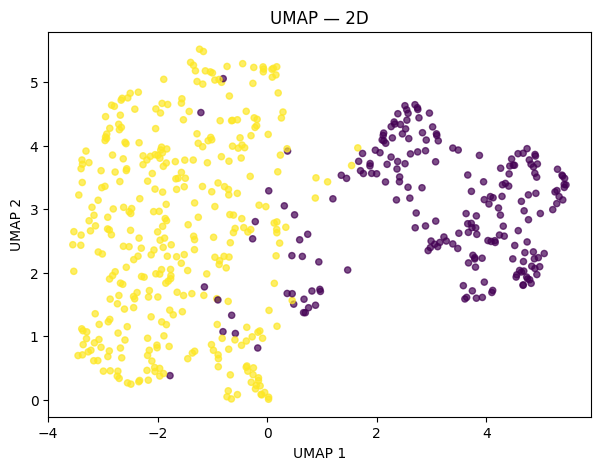

In [8]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=y,
    s=20,
    alpha=0.7
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP — 2D")
plt.show()

In [9]:
from sklearn.manifold import trustworthiness

tw_pca = trustworthiness(
    X_scaled,
    X_pca,
    n_neighbors=10
)

tw_tsne = trustworthiness(
    X_scaled,
    X_tsne,
    n_neighbors=10
)

tw_umap = trustworthiness(
    X_scaled,
    X_umap,
    n_neighbors=10
)

print("Trustworthiness:")
print("PCA :", round(tw_pca, 4))
print("t-SNE:", round(tw_tsne, 4))
print("UMAP :", round(tw_umap, 4))

Trustworthiness:
PCA : 0.8713
t-SNE: 0.9504
UMAP : 0.9307


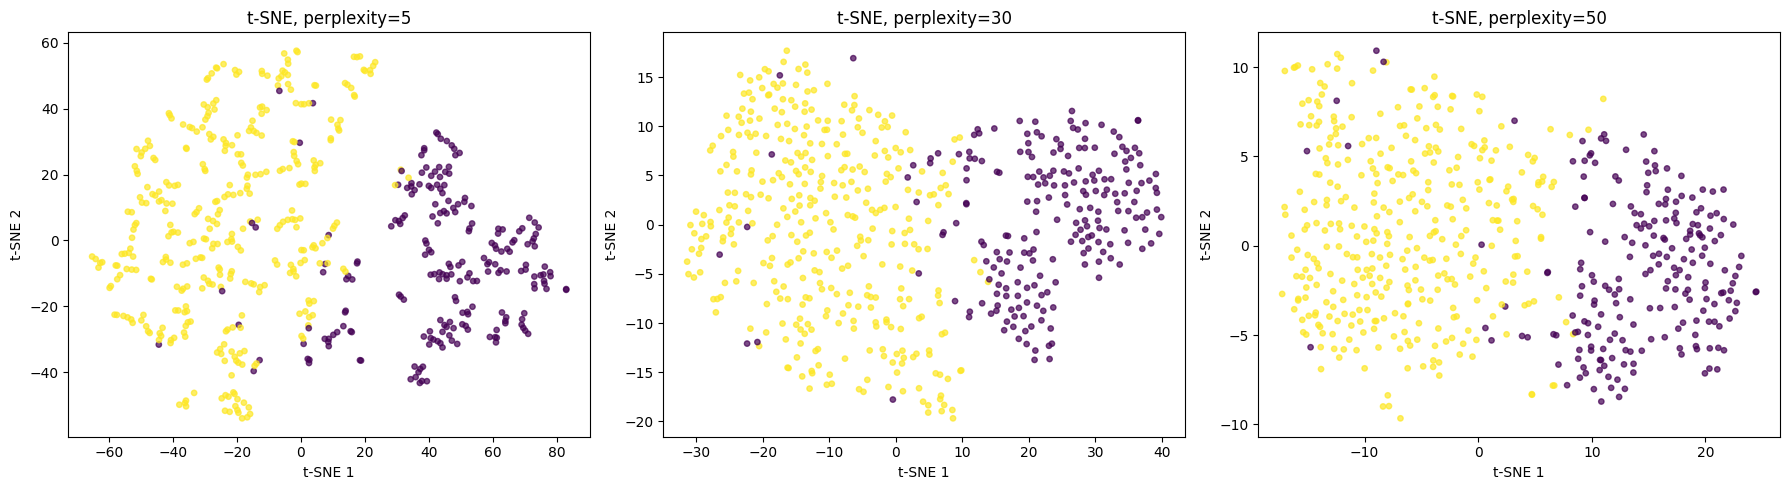

In [10]:
perplexities = [5, 30, 50]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, p in zip(axes, perplexities):

    tsne_p = TSNE(
        n_components=2,
        perplexity=p,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    Z = tsne_p.fit_transform(X_scaled)

    ax.scatter(
        Z[:, 0],
        Z[:, 1],
        c=y,
        s=15,
        alpha=0.7
    )

    ax.set_title(f"t-SNE, perplexity={p}")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

In [11]:
# t-SNE
tsne_test = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

tsne_test.fit_transform(X_scaled)

try:
    tsne_test.transform(X_scaled[:5])
except AttributeError as e:
    print("t-SNE transform:", e)

# UMAP
umap_test = umap.UMAP(
    n_components=2,
    random_state=42
)

umap_test.fit(X_scaled)

try:
    Z_new = umap_test.transform(X_scaled[:5])
    print("UMAP transform работает:", Z_new.shape)
except Exception as e:
    print("UMAP transform:", e)

t-SNE transform: 'TSNE' object has no attribute 'transform'


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP transform работает: (5, 2)


Уровень C

Для сравнения PCA, t-SNE и UMAP использовался датасет Breast Cancer из 30 признаков. Перед применением методов данные были масштабированы с помощью StandardScaler.

PCA

Первые две компоненты PCA объясняют:

[0.443, 0.190]

Суммарно:

0.632 = 63.2%

На двумерной визуализации два класса разделяются, однако между ними есть заметное пересечение.

t-SNE

Для t-SNE использовался perplexity=30.

t-SNE визуально разделяет два класса лучше, чем PCA. При этом расположение точек и форма групп отличаются от PCA.

UMAP

UMAP также показывает достаточно хорошее разделение двух классов. На графике видны отдельные области, соответствующие классам.

Trustworthiness

Метод

Trustworthiness

PCA

0.8713

t-SNE

0.9504

UMAP

0.9307

Наилучший результат по сохранению локальной структуры показал t-SNE — 0.9504. Вторым оказался UMAP — 0.9307, а PCA получил 0.8713.

Таким образом:

t-SNE > UMAP > PCA

по значению trustworthiness на данном эксперименте.

Влияние perplexity

Для t-SNE были проверены значения:

perplexity = 5
perplexity = 30
perplexity = 50

При изменении perplexity общая структура разделения классов сохраняется, однако форма и расположение групп заметно изменяются.

При perplexity=5 t-SNE сильнее ориентируется на ближайших соседей, поэтому представление получается более фрагментированным.

При perplexity=30 разделение выглядит достаточно стабильным.

При perplexity=50 классы также разделяются, но форма и расположение облаков снова меняются.

Следовательно, t-SNE чувствителен к параметру perplexity, поэтому результат визуализации необходимо интерпретировать с учётом выбранного параметра.

Проверка transform

Для t-SNE была выполнена попытка применить:

tsne_test.transform(X_scaled[:5])

Получен результат:

'tSNE' object has no attribute 'transform'

Следовательно, t-SNE не имеет метода transform для новых объектов в используемой реализации.

Для UMAP:

UMAP transform работает: (5, 2)

То есть UMAP может преобразовывать новые объекты после обучения.

Вывод по уровню C

PCA, t-SNE и UMAP подходят для разных задач.

PCA является линейным методом уменьшения размерности и может использоваться непосредственно в обучающем pipeline. Он также имеет transform для новых объектов.

t-SNE хорошо сохраняет локальную структуру и дал наибольший trustworthiness — 0.9504, но не имеет transform для новых объектов. Поэтому его следует использовать преимущественно как инструмент визуализации.

UMAP также хорошо сохраняет локальную структуру и показал trustworthiness 0.9307. В отличие от t-SNE, UMAP поддерживает transform, поэтому его можно применять не только для визуализации, но и в pipeline для преобразования новых объектов.

Итог для всех уровней

PCA оправдан как метод уменьшения размерности и визуализации. На данных клиентов ПР-10 две компоненты сохранили 92.2% дисперсии, поэтому PCA оказался особенно эффективным для визуального представления сегментов.

На данных Breast Cancer две компоненты сохранили только 63.2% дисперсии, поэтому для сохранения 90% информации потребовалось 7 компонент.

В эксперименте с Logistic Regression использование PCA не улучшило максимальное качество модели: лучший результат на тестовой выборке получен без PCA — 0.9825. Однако PCA 95% позволил уменьшить число признаков с 30 до 10 при сохранении высокого качества.

Сравнение методов визуализации показало, что t-SNE и UMAP лучше сохраняют локальную структуру данных по сравнению с PCA. Однако t-SNE подходит главным образом для визуализации, поскольку не поддерживает transform новых объектов. PCA и UMAP могут использоваться в обучающих pipeline.